<a href="https://colab.research.google.com/github/Sangita-Giri/PYTHON/blob/main/California_Housing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files
uploaded = files.upload()


Saving california_housing (1).csv to california_housing (1).csv


In [3]:
import pandas as pd
df = pd.read_csv('california_housing (1).csv')

df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [4]:
df.shape

(20640, 10)

In [5]:
df.columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [8]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [12]:
df.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,207
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
# Handle missing values
median_value = df['total_bedrooms'].median()

df['total_bedrooms'] = df['total_bedrooms'].fillna(median_value)

# Verify missing values
print(df.isnull().sum())

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64


In [15]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,536.838857,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,419.391878,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,297.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,643.250000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

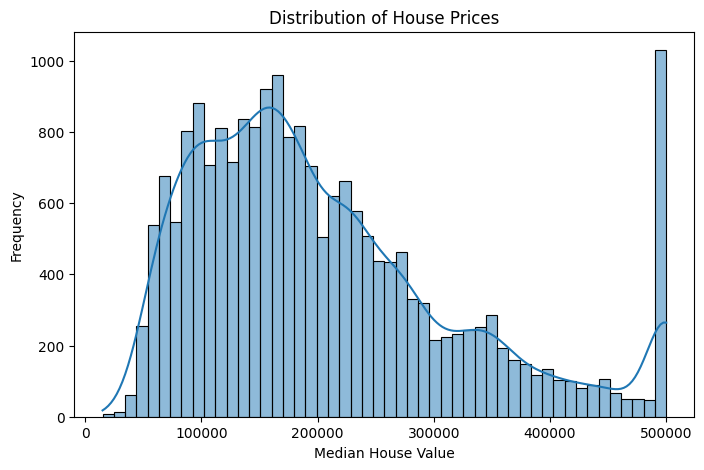

In [17]:
plt.figure(figsize=(8,5))

sns.histplot(df['median_house_value'], bins=50, kde=True)

plt.title('Distribution of House Prices')
plt.xlabel('Median House Value')
plt.ylabel('Frequency')

plt.show()

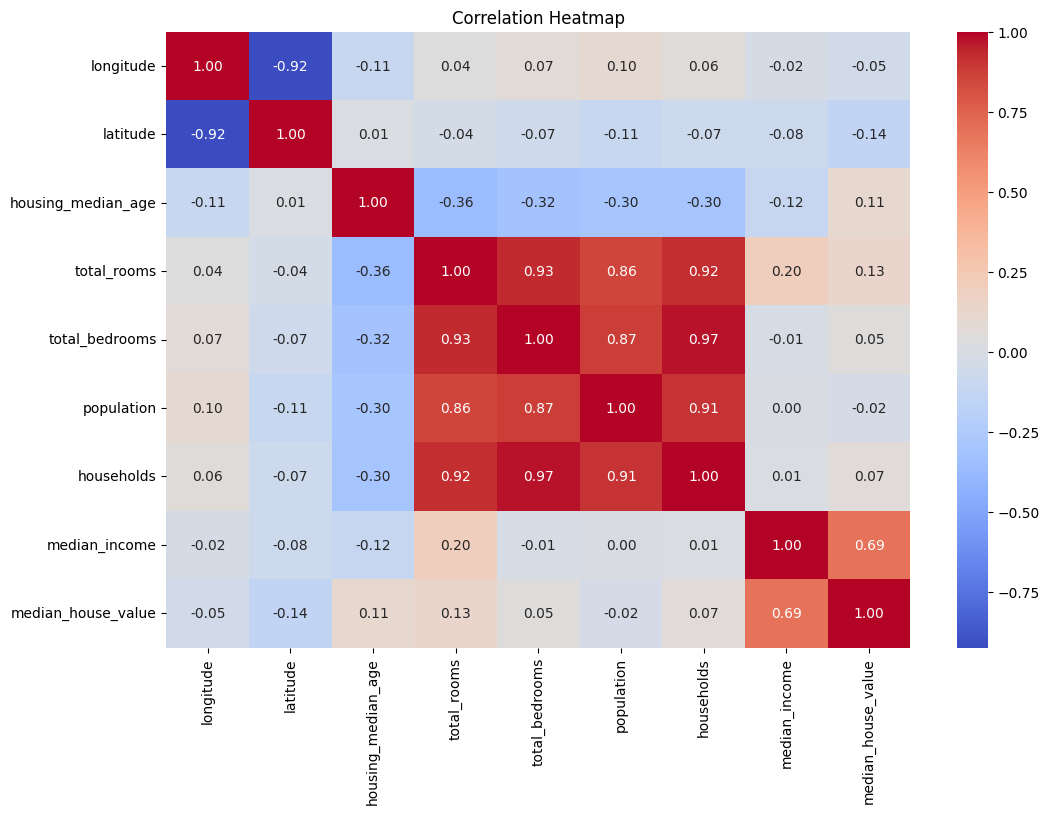

In [18]:
plt.figure(figsize=(12,8))

sns.heatmap(
    df.select_dtypes(include='number').corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

In [19]:
# Separate input and target
X = df.drop('median_house_value', axis=1)
y = df['median_house_value']

print(X.shape)
print(y.shape)

(20640, 9)
(20640,)


In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (16512, 9)
Testing data: (4128, 9)


In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

# Identify numerical and categorical columns
num_cols = X.select_dtypes(include='number').columns
cat_cols = X.select_dtypes(include='object').columns

# Convert categorical data into numbers
preprocessor = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
], remainder='passthrough')

# Create Linear Regression pipeline
model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

# Train model
model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [22]:
y_pred = model.predict(X_test)

print("Actual prices:", y_test.head().values)
print("Predicted prices:", y_pred[:5])

Actual prices: [ 47700.  45800. 500001. 218600. 278000.]
Predicted prices: [ 54055.448899   124225.33893723 255489.3794917  268002.43156923
 262769.43481569]


In [23]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

print("MAE:", mean_absolute_error(y_test, y_pred))

print("MSE:", mean_squared_error(y_test, y_pred))

print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

print("R2 Score:", r2_score(y_test, y_pred))

MAE: 50670.73824097227
MSE: 4908476721.156336
RMSE: 70060.52184473319
R2 Score: 0.6254240620553819


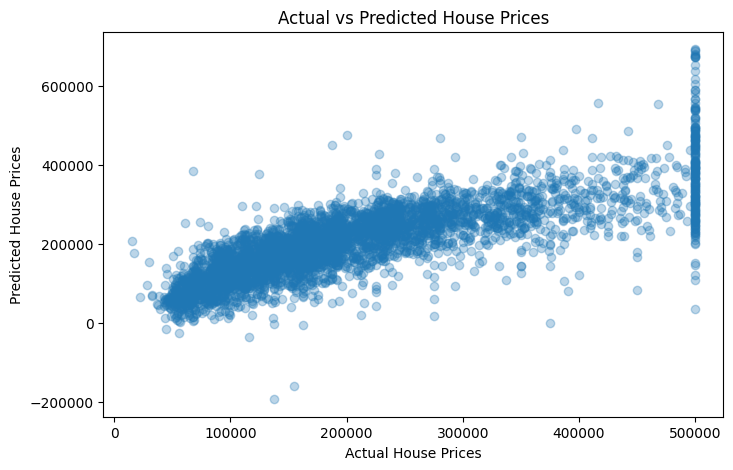

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.scatter(y_test, y_pred, alpha=0.3)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")

plt.title("Actual vs Predicted House Prices")

plt.show()

In [25]:
# Create classification target

df['price_category'] = (
    df['median_house_value'] >= df['median_house_value'].median()
).astype(int)

# Check the categories
print(df['price_category'].value_counts())

price_category
1    10325
0    10315
Name: count, dtype: int64


In [26]:
X = df.drop(
    ['median_house_value', 'price_category'],
    axis=1
)

y = df['price_category']

In [27]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(16512, 9)
(4128, 9)


In [28]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

model = make_pipeline(preprocessor, LogisticRegression(max_iter=1000))

model.fit(X_train, y_train)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income'],
      dtype='object')),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['ocean_proximity'], dtype='object'))])),
                ('logisticregression', LogisticRegression(max_iter=1000))])

In [29]:
y_pred = model.predict(X_test)
print(y_pred[:10])

[0 0 1 1 1 0 0 0 1 0]


In [30]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.8389050387596899
              precision    recall  f1-score   support

           0       0.85      0.83      0.84      2063
           1       0.83      0.85      0.84      2065

    accuracy                           0.84      4128
   macro avg       0.84      0.84      0.84      4128
weighted avg       0.84      0.84      0.84      4128

[[1712  351]
 [ 314 1751]]


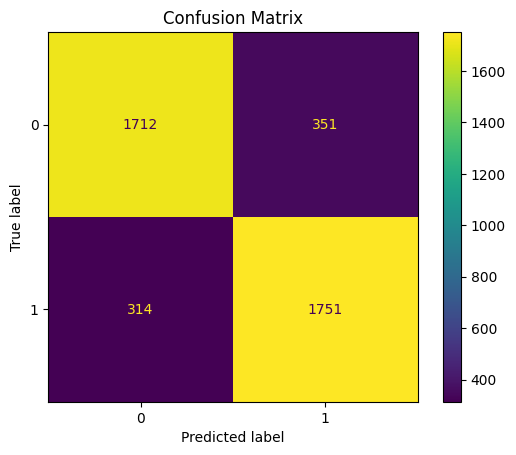

In [31]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Confusion Matrix")
plt.show()

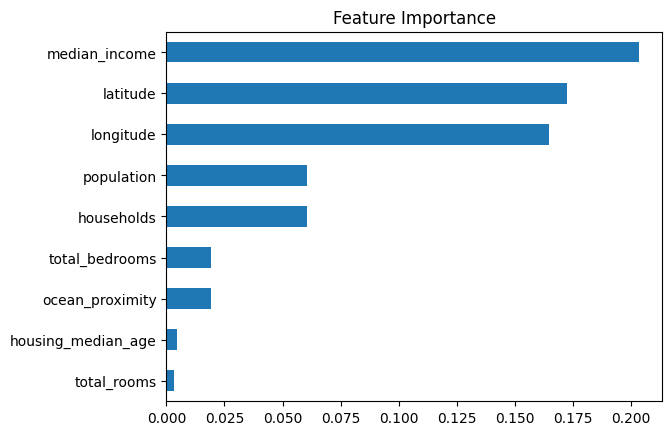

In [34]:
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

result = permutation_importance(
    model, X_test, y_test,
    n_repeats=5,
    random_state=42
)

importance = pd.Series(
    result.importances_mean,
    index=X.columns
).sort_values()

importance.plot(kind='barh', title='Feature Importance')
plt.show()

In [36]:
# Predict house prices using the trained model
y_pred = model.predict(X_test)

print("Actual Values:", y_test[:5])
print("Predicted Values:", y_pred[:5])

Actual Values: 7268     0
2285     0
10971    1
15502    1
14907    0
Name: price_category, dtype: int64
Predicted Values: [0 0 1 1 1]


In [39]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

n = X_test.shape[0]
k = X_test.shape[1]

adjusted_r2 = 1 - (1-r2) * (n-1)/(n-k-1)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)
print("Adjusted R2:", adjusted_r2)

MAE: 0.1610949612403101
MSE: 0.1610949612403101
RMSE: 0.4013663678490141
R2 Score: 0.3556200037792582
Adjusted R2: 0.3542116939283628


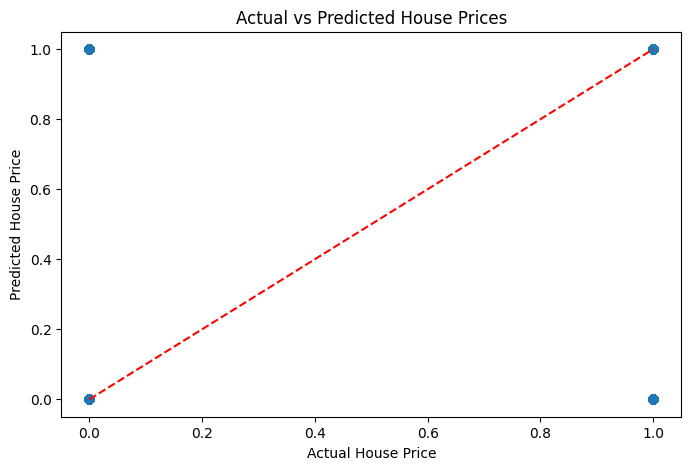

In [40]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.4)

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Actual vs Predicted House Prices")

plt.plot(
    [min(y_test), max(y_test)],
    [min(y_test), max(y_test)],
    'r--'
)

plt.show()

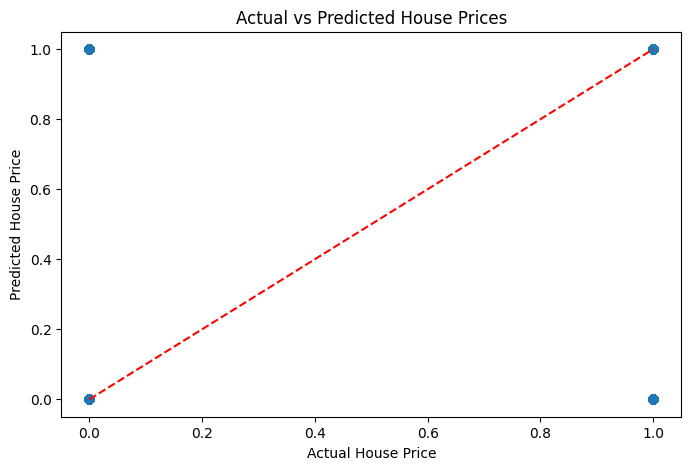

In [41]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel("Actual House Price")
plt.ylabel("Predicted House Price")
plt.title("Actual vs Predicted House Prices")

plt.plot(
    [min(y_test), max(y_test)],
    [min(y_test), max(y_test)],
    'r--'
)

plt.show()

In [42]:
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)
print("Predicted shape:", y_pred.shape)

print("Number of actual values:", len(y_test))
print("Number of predicted values:", len(y_pred))

X_test shape: (4128, 9)
y_test shape: (4128,)
Predicted shape: (4128,)
Number of actual values: 4128
Number of predicted values: 4128


In [43]:
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2:", r2)
print("Adjusted R2:", adjusted_r2)

MAE: 0.1610949612403101
MSE: 0.1610949612403101
RMSE: 0.4013663678490141
R2: 0.3556200037792582
Adjusted R2: 0.3542116939283628


In [44]:
print("Actual values:")
print(y_test.describe())

print("\nPredicted values:")
print(pd.Series(y_pred).describe())

print("\nModel type:")
print(type(model))

Actual values:
count    4128.000000
mean        0.500242
std         0.500061
min         0.000000
25%         0.000000
50%         1.000000
75%         1.000000
max         1.000000
Name: price_category, dtype: float64

Predicted values:
count    4128.000000
mean        0.509205
std         0.499976
min         0.000000
25%         0.000000
50%         1.000000
75%         1.000000
max         1.000000
dtype: float64

Model type:
<class 'sklearn.pipeline.Pipeline'>


In [45]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Generate predictions
y_pred = model.predict(X_test)

# Calculate metrics
print("Accuracy:", accuracy_score(y_test, y_pred))

print("Precision:", precision_score(y_test, y_pred))

print("Recall:", recall_score(y_test, y_pred))

print("F1 Score:", f1_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.8389050387596899
Precision: 0.8330161750713606
Recall: 0.8479418886198548
F1 Score: 0.8404127669786418

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.83      0.84      2063
           1       0.83      0.85      0.84      2065

    accuracy                           0.84      4128
   macro avg       0.84      0.84      0.84      4128
weighted avg       0.84      0.84      0.84      4128


Confusion Matrix:
[[1712  351]
 [ 314 1751]]


In [47]:
print("Pipeline steps:")
print(model.named_steps)

print("\nPipeline parameters:")
print(model.get_params().keys())

Pipeline steps:
{'columntransformer': ColumnTransformer(transformers=[('num', StandardScaler(),
                                 Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income'],
      dtype='object')),
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
                                 Index(['ocean_proximity'], dtype='object'))]), 'logisticregression': LogisticRegression(max_iter=1000)}

Pipeline parameters:
dict_keys(['memory', 'steps', 'transform_input', 'verbose', 'columntransformer', 'logisticregression', 'columntransformer__force_int_remainder_cols', 'columntransformer__n_jobs', 'columntransformer__remainder', 'columntransformer__sparse_threshold', 'columntransformer__transformer_weights', 'columntransformer__transformers', 'columntransformer__verbose', 'columntransformer__verbose_feature_names_out', 'columntransformer__num', 'columntransformer__cat', 'columntran

In [52]:
print("Pipeline step names:")

print(list(model.named_steps.keys()))

print("\nPipeline step details:")

for name, step in model.named_steps.items():
    print(name)
    print(type(step))
    print("----------------")

Pipeline step names:
['columntransformer', 'logisticregression']

Pipeline step details:
columntransformer
<class 'sklearn.compose._column_transformer.ColumnTransformer'>
----------------
logisticregression
<class 'sklearn.linear_model._logistic.LogisticRegression'>
----------------


In [53]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, f1_score

In [54]:
param_grid = {
    'logisticregression__C': [0.01, 0.1, 1, 10, 100],
    'logisticregression__class_weight': [None, 'balanced'],
    'logisticregression__max_iter': [500, 1000]
}

In [55]:
grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("Best Cross Validation F1 Score:")
print(grid_search.best_score_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Parameters:
{'logisticregression__C': 10, 'logisticregression__class_weight': None, 'logisticregression__max_iter': 500}
Best Cross Validation F1 Score:
0.8396012224060844


In [56]:
best_model = grid_search.best_estimator_

y_pred_tuned = best_model.predict(X_test)

print("Tuned Model Accuracy:",
      accuracy_score(y_test, y_pred_tuned))

print("Tuned Model F1 Score:",
      f1_score(y_test, y_pred_tuned))

Tuned Model Accuracy: 0.8386627906976745
Tuned Model F1 Score: 0.8402877697841726


In [57]:
print("Original Accuracy:",
      accuracy_score(y_test, model.predict(X_test)))

print("Tuned Accuracy:",
      accuracy_score(y_test, y_pred_tuned))

Original Accuracy: 0.8389050387596899
Tuned Accuracy: 0.8386627906976745


In [58]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

y_pred_original = model.predict(X_test)

print("ORIGINAL MODEL")
print("Accuracy:", accuracy_score(y_test, y_pred_original))
print("Precision:", precision_score(y_test, y_pred_original))
print("Recall:", recall_score(y_test, y_pred_original))
print("F1 Score:", f1_score(y_test, y_pred_original))

print("\nTUNED MODEL")
print("Accuracy:", accuracy_score(y_test, y_pred_tuned))
print("Precision:", precision_score(y_test, y_pred_tuned))
print("Recall:", recall_score(y_test, y_pred_tuned))
print("F1 Score:", f1_score(y_test, y_pred_tuned))

print("\nBest Parameters:")
print(grid_search.best_params_)

ORIGINAL MODEL
Accuracy: 0.8389050387596899
Precision: 0.8330161750713606
Recall: 0.8479418886198548
F1 Score: 0.8404127669786418

TUNED MODEL
Accuracy: 0.8386627906976745
Precision: 0.8323040380047506
Recall: 0.8484261501210654
F1 Score: 0.8402877697841726

Best Parameters:
{'logisticregression__C': 10, 'logisticregression__class_weight': None, 'logisticregression__max_iter': 500}


In [59]:
# Select the original model
final_model = model

# Generate final predictions
final_predictions = final_model.predict(X_test)

from sklearn.metrics import accuracy_score, classification_report

print("FINAL MODEL: LOGISTIC REGRESSION")

print("Final Accuracy:",
      accuracy_score(y_test, final_predictions))

print("\nFinal Classification Report:")
print(classification_report(y_test, final_predictions))

FINAL MODEL: LOGISTIC REGRESSION
Final Accuracy: 0.8389050387596899

Final Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.83      0.84      2063
           1       0.83      0.85      0.84      2065

    accuracy                           0.84      4128
   macro avg       0.84      0.84      0.84      4128
weighted avg       0.84      0.84      0.84      4128



In [60]:
import joblib

joblib.dump(final_model, "house_price_model.pkl")

print("Final model saved successfully!")

Final model saved successfully!


In [61]:
import joblib

loaded_model = joblib.load("house_price_model.pkl")
print("Model loaded successfully")

Model loaded successfully


In [63]:
import pandas as pd

new_house = pd.DataFrame([{
    'longitude': -122.23,
    'latitude': 37.88,
    'housing_median_age': 30,
    'total_rooms': 2000,
    'total_bedrooms': 400,
    'population': 1000,
    'households': 350,
    'median_income': 4.5,
    'ocean_proximity': 'NEAR BAY'
}])

new_house = new_house[X_train.columns]

In [64]:
prediction = loaded_model.predict(new_house)

if prediction[0] == 0:
    print("House Price Category: Below or equal to median")
else:
    print("House Price Category: Above median")

House Price Category: Above median


In [65]:
probability = loaded_model.predict_proba(new_house)

print("Category 0 probability:", probability[0][0])
print("Category 1 probability:", probability[0][1])

Category 0 probability: 0.21556443512602463
Category 1 probability: 0.7844355648739754
